# VIPY · Análisis de la evidencia del anteproyecto

**Control de acceso con credenciales digitales verificables por NFC y QR**

| Dato | Detalle |
|---|---|
| Equipo | Ronald García Muñoz · Luis Miguel Muñoz Rendón |
| Asesor técnico | Rodolfo Ortega |
| Curso | Ideación, Emprendimiento y Desarrollo Tecnológico · Ingeniería de Software · Universidad Cooperativa de Colombia |
| Fuente | Documento final del anteproyecto (E8): encuesta exploratoria (Anexo A), entrevistas (Anexos B y C), Tablas III, XVI y XVIII |

Este cuaderno reúne en un solo lugar los números que sostienen el anteproyecto y los convierte en gráficas. También deja los datos en archivos CSV listos para abrir en Power BI.

> **Sobre los datos.** Las respuestas individuales de la encuesta no se publican porque contienen datos de terceros. Aquí se usan los **conteos agregados** que aparecen en el documento final. La encuesta es exploratoria y por conveniencia (n = 22 respuestas válidas de 31), así que **no es representativa**: sirve para orientar el diseño, no para generalizar.

## 1. Preparación

Cargo las librerías y defino una paleta de colores única para todas las gráficas.

In [1]:
%config InlineBackend.figure_formats = ["png"]
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight"}
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

AZUL, NARANJA, MORADO, VERDE, GRIS = "#118DFF", "#E66C37", "#744EC2", "#1AAB40", "#C8C6C4"
plt.rcParams.update({
    "figure.dpi": 96, "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.grid": True, "axes.grid.axis": "x",
    "grid.color": "#EDEBE9", "axes.axisbelow": True, "font.size": 10.5,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
})
N = 22  # respuestas válidas de la encuesta

## 2. Los datos

Cada tabla sale del documento final. Las guardo también como CSV para el tablero de Power BI.

In [2]:
control = pd.DataFrame({
    "forma": ["Manilla, sello o tarjeta", "Cédula", "Lista", "QR en el celular", "Lector automático", "Sin control (declarado)"],
    "personas": [11, 10, 2, 1, 0, 9],
})
espera = pd.DataFrame({"espera": ["Menos de 5 min", "De 5 a 15 min", "Más de 15 min"], "personas": [12, 6, 4]})
copia = pd.DataFrame({"respuesta": ["Lo vieron", "Lo supieron", "No lo han visto ni sabido"], "personas": [6, 6, 10]})
telefonos = pd.DataFrame({
    "sistema": ["iPhone", "Android", "Android", "Android"],
    "nfc": ["No aplica", "Sí", "No", "No sabe"],
    "personas": [11, 4, 5, 2],
})
indicadores = pd.DataFrame({
    "indicador": ["Control manual en la última visita", "Se han ido de un lugar por la fila",
                  "Vieron o supieron de una credencial copiada", "Entraron a dos o más lugares",
                  "Tienen dos o más credenciales"],
    "personas": [16, 18, 12, 17, 6],
})
control["porcentaje"] = (control["personas"] / N * 100).round(0)
control

,forma,personas,porcentaje
0,"Manilla, sello o tarjeta",11,50.0
1,Cédula,10,45.0
2,Lista,2,9.0
3,QR en el celular,1,5.0
4,Lector automático,0,0.0
5,Sin control (declarado),9,41.0


La pregunta de forma de control admitía varias respuestas, por eso la suma pasa de 22. Tres personas marcaron “sin control” junto con otra opción; el documento las reporta como respuestas inconsistentes. El intervalo “de 5 a 15 min” es el resto de la muestra: 22 − 12 − 4 = 6.

## 3. ¿Cómo se entra hoy?

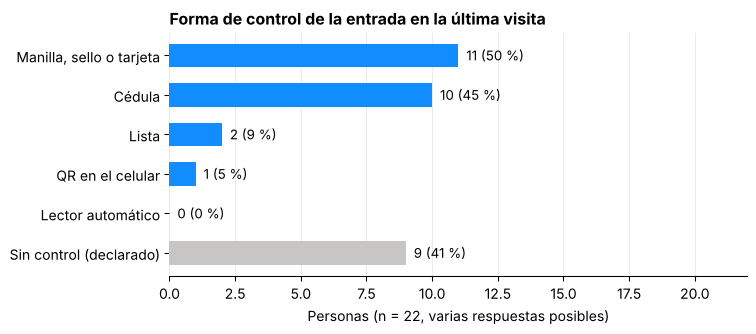

In [3]:
d = control.iloc[::-1]
colores = [GRIS if "Sin control" in f else AZUL for f in d["forma"]]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(d["forma"], d["personas"], color=colores, height=0.6)
for y, (v, p) in enumerate(zip(d["personas"], d["porcentaje"])):
    ax.text(v + 0.3, y, f"{v} ({p:.0f} %)", va="center", fontsize=10)
ax.set_xlim(0, N)
ax.set_xlabel("Personas (n = 22, varias respuestas posibles)")
ax.set_title("Forma de control de la entrada en la última visita")
plt.tight_layout(); plt.show()

**Lectura.** La revisión manual domina: manilla o tarjeta (11) y cédula (10). Solo una persona mostró un QR y nadie usó un lector automático. Con una muestra tan pequeña conviene ver el margen de error de la cifra principal, 16 de 22 con control manual.

In [4]:
def wilson(k, n, z=1.96):
    p = k / n
    centro = (p + z**2 / (2*n)) / (1 + z**2 / n)
    margen = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / (1 + z**2 / n)
    return centro - margen, centro + margen

filas = []
for _, r in indicadores.iterrows():
    lo, hi = wilson(r["personas"], N)
    filas.append([r["indicador"], r["personas"], round(r["personas"]/N*100), round(lo*100), round(hi*100)])
tabla_ic = pd.DataFrame(filas, columns=["indicador", "personas", "% muestra", "IC95 bajo %", "IC95 alto %"])
tabla_ic

,indicador,personas,% muestra,IC95 bajo %,IC95 alto %
0,Control manual en la última visita,16,73,52,87
1,Se han ido de un lugar por la fila,18,82,61,93
2,Vieron o supieron de una credencial copiada,12,55,35,73
3,Entraron a dos o más lugares,17,77,57,90
4,Tienen dos o más credenciales,6,27,13,48


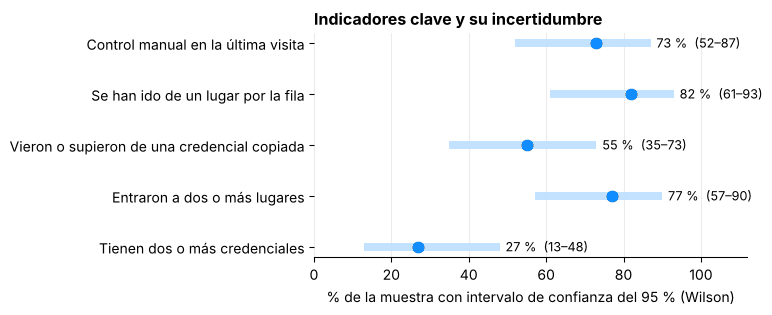

In [5]:
t = tabla_ic.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 3.4))
y = np.arange(len(t))
ax.hlines(y, t["IC95 bajo %"], t["IC95 alto %"], color=AZUL, lw=6, alpha=.25)
ax.plot(t["% muestra"], y, "o", color=AZUL, ms=8)
for yi, (p, lo, hi) in enumerate(zip(t["% muestra"], t["IC95 bajo %"], t["IC95 alto %"])):
    ax.text(hi + 1.5, yi, f"{p} %  ({lo}–{hi})", va="center", fontsize=9.5)
ax.set_yticks(y, t["indicador"]); ax.set_xlim(0, 112)
ax.set_xlabel("% de la muestra con intervalo de confianza del 95 % (Wilson)")
ax.set_title("Indicadores clave y su incertidumbre")
plt.tight_layout(); plt.show()

**Lectura.** Aun en el extremo bajo del intervalo, más de la mitad de las personas tuvo un control manual (≈ 52 %) y la mayoría se ha ido alguna vez por la fila (≈ 61 %). Los intervalos son anchos porque n = 22: por eso el plan incluye una **encuesta ampliada** (≥ 50 respuestas) en la fase F1.

## 4. Espera y copias

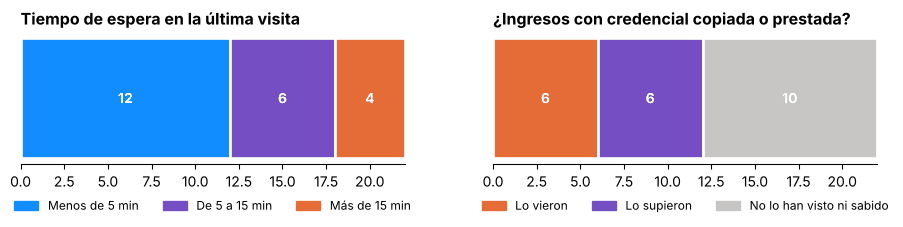

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 2.6))
for ax, df, col, cols, titulo in [
    (axes[0], espera, "espera", [AZUL, MORADO, NARANJA], "Tiempo de espera en la última visita"),
    (axes[1], copia, "respuesta", [NARANJA, MORADO, GRIS], "¿Ingresos con credencial copiada o prestada?"),
]:
    izq = 0
    for (etq, v), c in zip(df[[col, "personas"]].values, cols):
        ax.barh(0, v, left=izq, color=c, height=0.5, edgecolor="white", linewidth=2)
        ax.text(izq + v/2, 0, f"{v}", ha="center", va="center", color="white", fontweight="bold")
        izq += v
    ax.set_xlim(0, N); ax.set_yticks([]); ax.grid(False); ax.set_title(titulo)
    ax.legend(handles=[Patch(color=c, label=e) for e, c in zip(df[col], cols)],
              loc="upper center", bbox_to_anchor=(.5, -0.18), ncol=3, frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

**Lectura.** La mayoría esperó menos de 5 minutos, pero las esperas largas existen (4 de 22) y se concentran en horas pico y eventos, como contó el portero entrevistado (filas de unos 30 minutos). Más de la mitad (12 de 22) conoce casos de credenciales copiadas o prestadas: el fenómeno es conocido, aunque la encuesta no mide su frecuencia.

## 5. Teléfonos: ¿quién puede usar cada canal?

Esta es la razón por la que VIPY combina NFC con un QR firmado.

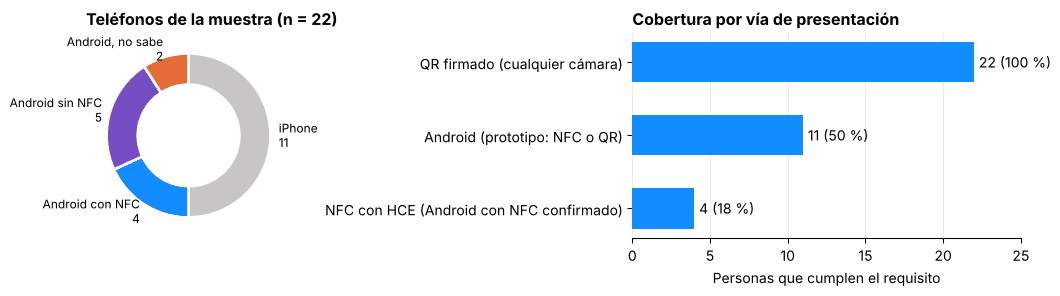

In [7]:
canales = pd.DataFrame({
    "canal": ["QR firmado (cualquier cámara)", "Android (prototipo: NFC o QR)", "NFC con HCE (Android con NFC confirmado)"],
    "personas": [22, 11, 4],
})
canales["porcentaje"] = (canales["personas"] / N * 100).round(0)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]
etq = ["iPhone", "Android con NFC", "Android sin NFC", "Android, no sabe"]
vals = telefonos["personas"].tolist(); cols = [GRIS, AZUL, MORADO, NARANJA]
ax.pie(vals, labels=[f"{e}\n{v}" for e, v in zip(etq, vals)], colors=cols, startangle=90,
       counterclock=False, wedgeprops={"width": .38, "edgecolor": "white", "linewidth": 2}, textprops={"fontsize": 9})
ax.set_title("Teléfonos de la muestra (n = 22)")
ax = axes[1]
d = canales.iloc[::-1]
ax.barh(d["canal"], d["personas"], color=AZUL, height=.55)
for yi, (v, p) in enumerate(zip(d["personas"], d["porcentaje"])):
    ax.text(v + .3, yi, f"{v} ({p:.0f} %)", va="center")
ax.set_xlim(0, N + 3); ax.set_xlabel("Personas que cumplen el requisito")
ax.set_title("Cobertura por vía de presentación")
plt.tight_layout(); plt.show()

**Lectura.** La mitad de la muestra usa iPhone, y de los 11 usuarios de Android solo 4 confirman tener NFC. Si VIPY dependiera solo de NFC, hoy cubriría al 18 % de la muestra. El QR bidireccional firmado no depende del NFC, por eso es el canal alterno. La cobertura (condición C4) se mide y se reporta en el piloto.

## 6. La brecha: 13 alternativas frente a C1, C2 y C3

C1 = sin hardware en la puerta · C2 = autentica al titular · C3 = credencial persistente y multisitio. Codifico la Tabla III como 1 = sí, 0,5 = parcial o depende, 0 = no.

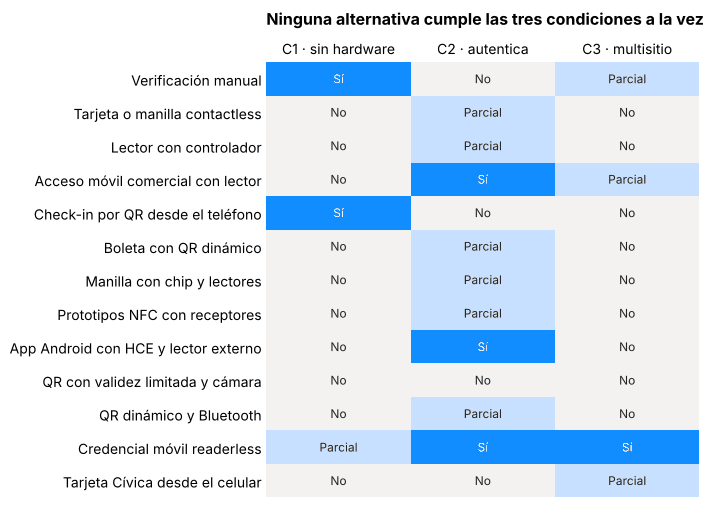

,alternativa,C1,C2,C3,cumple_completo
11,Credencial móvil readerless,0.5,1.0,1.0,2
4,Check-in por QR desde el teléfono,1.0,0.0,0.0,1
3,Acceso móvil comercial con lector,0.0,1.0,0.5,1
8,App Android con HCE y lector externo,0.0,1.0,0.0,1


In [8]:
alternativas = pd.DataFrame([
    ["Verificación manual", 1, 0, .5], ["Tarjeta o manilla contactless", 0, .5, 0],
    ["Lector con controlador", 0, .5, 0], ["Acceso móvil comercial con lector", 0, 1, .5],
    ["Check-in por QR desde el teléfono", 1, 0, 0], ["Boleta con QR dinámico", 0, .5, 0],
    ["Manilla con chip y lectores", 0, .5, 0], ["Prototipos NFC con receptores", 0, .5, 0],
    ["App Android con HCE y lector externo", 0, 1, 0], ["QR con validez limitada y cámara", 0, 0, 0],
    ["QR dinámico y Bluetooth", 0, .5, 0], ["Credencial móvil readerless", .5, 1, 1],
    ["Tarjeta Cívica desde el celular", 0, 0, .5],
], columns=["alternativa", "C1", "C2", "C3"])
alternativas["cumple_completo"] = (alternativas[["C1", "C2", "C3"]] == 1).sum(axis=1)

from matplotlib.colors import ListedColormap
cmap = ListedColormap(["#F3F2F1", "#C7E0FF", AZUL])
fig, ax = plt.subplots(figsize=(7.5, 5.4))
m = alternativas[["C1", "C2", "C3"]].values
ax.imshow(m, cmap=cmap, aspect="auto", vmin=0, vmax=1)
txt = {0: "No", .5: "Parcial", 1: "Sí"}
for i in range(m.shape[0]):
    for j in range(3):
        ax.text(j, i, txt[m[i, j]], ha="center", va="center", fontsize=9, color="white" if m[i, j] == 1 else "#252423")
ax.set_xticks(range(3), ["C1 · sin hardware", "C2 · autentica", "C3 · multisitio"])
ax.set_yticks(range(len(alternativas)), alternativas["alternativa"])
ax.tick_params(length=0); ax.grid(False); ax.xaxis.tick_top()
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("Ninguna alternativa cumple las tres condiciones a la vez", pad=28)
plt.tight_layout(); plt.show()
alternativas.sort_values("cumple_completo", ascending=False).head(4)

**Lectura.** La que más se acerca, la credencial móvil *readerless*, cumple dos condiciones completas y la tercera solo en parte (necesita una placa por puerta). Las opciones sin hardware validan códigos que se pueden copiar; las que autentican necesitan lector. Ese hueco es el que el prototipo VIPY quiere cubrir.

## 7. Plan de 16 semanas

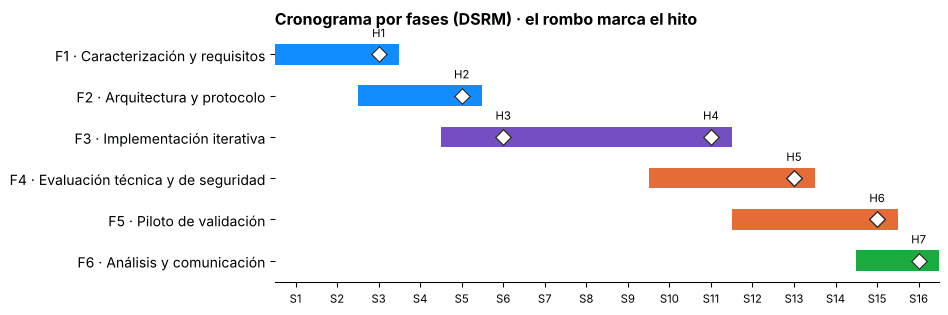

In [9]:
fases = pd.DataFrame([
    ["F1 · Caracterización y requisitos", 1, 3], ["F2 · Arquitectura y protocolo", 3, 5],
    ["F3 · Implementación iterativa", 5, 11], ["F4 · Evaluación técnica y de seguridad", 10, 13],
    ["F5 · Piloto de validación", 12, 15], ["F6 · Análisis y comunicación", 15, 16],
], columns=["fase", "inicio", "fin"])
hitos = pd.DataFrame([
    ["H1", 3, 0, "Requisitos aprobados"], ["H2", 5, 1, "Protocolo aprobado"], ["H3", 6, 2, "Canal NFC entre dos teléfonos"],
    ["H4", 11, 2, "Versión evaluada"], ["H5", 13, 3, "Evaluación técnica cerrada"], ["H6", 15, 4, "Piloto ejecutado"],
    ["H7", 16, 5, "Cierre del proyecto"],
], columns=["hito", "semana", "fila", "descripcion"])
colores_fase = [AZUL, AZUL, MORADO, NARANJA, NARANJA, VERDE]

fig, ax = plt.subplots(figsize=(10, 3.4))
for i, (f, a, z) in enumerate(fases.values):
    ax.barh(i, z - a + 1, left=a - .5, color=colores_fase[i], height=.5)
ax.scatter(hitos["semana"], hitos["fila"], marker="D", s=70, color="white", edgecolor="#252423", zorder=3)
for _, h in hitos.iterrows():
    ax.text(h["semana"], h["fila"] - .42, h["hito"], ha="center", fontsize=8.5)
ax.set_yticks(range(len(fases)), fases["fase"]); ax.invert_yaxis()
ax.set_xticks(range(1, 17), [f"S{s}" for s in range(1, 17)], fontsize=8.5)
ax.set_xlim(.5, 16.5); ax.grid(axis="x")
ax.set_title("Cronograma por fases (DSRM) · el rombo marca el hito")
plt.tight_layout(); plt.show()

## 8. Presupuesto valorado

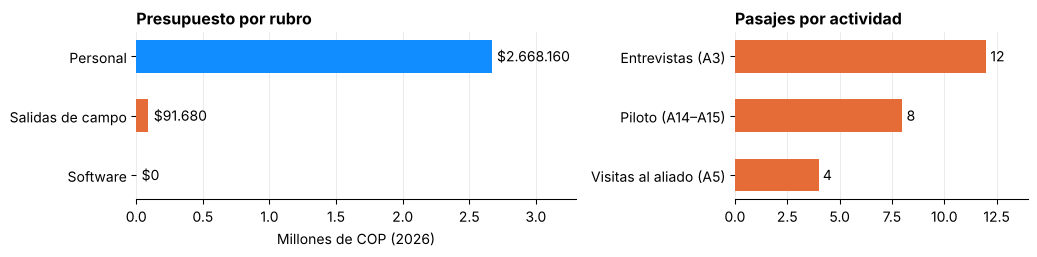

Total valorado: $ 2.759.840 COP + rubros pendientes de cotizar


In [10]:
presupuesto = pd.DataFrame([
    ["Personal", "Dedicación de los dos estudiantes (320 h × $8.338)", 2668160, "Equipo · especie"],
    ["Salidas de campo", "24 pasajes de Metro × $3.820", 91680, "Equipo · efectivo"],
    ["Software", "Android Studio, Kotlin, GitHub, Google Forms, Firebase Spark", 0, "Sin costo"],
], columns=["rubro", "detalle", "valor_cop", "fuente"])
pasajes = pd.DataFrame([["Entrevistas (A3)", 12], ["Piloto (A14–A15)", 8], ["Visitas al aliado (A5)", 4]], columns=["actividad", "pasajes"])
pasajes["valor_cop"] = pasajes["pasajes"] * 3820

fig, axes = plt.subplots(1, 2, figsize=(11, 2.8), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]; d = presupuesto.iloc[::-1]
ax.barh(d["rubro"], d["valor_cop"] / 1e6, color=[AZUL, NARANJA, AZUL][::-1], height=.55)
for yi, v in enumerate(d["valor_cop"]):
    ax.text(v / 1e6 + .04, yi, f"${v:,.0f}".replace(",", "."), va="center")
ax.set_xlim(0, 3.3); ax.set_xlabel("Millones de COP (2026)"); ax.set_title("Presupuesto por rubro")
ax = axes[1]; d = pasajes.iloc[::-1]
ax.barh(d["actividad"], d["pasajes"], color=NARANJA, height=.55)
for yi, v in enumerate(d["pasajes"]):
    ax.text(v + .2, yi, str(v), va="center")
ax.set_xlim(0, 14); ax.set_title("Pasajes por actividad")
plt.tight_layout(); plt.show()
print("Total valorado: $", f"{presupuesto['valor_cop'].sum():,.0f}".replace(",", "."), "COP + rubros pendientes de cotizar")

**Lectura.** Casi todo el valor es tiempo del equipo. Todavía no hay cotización para los teléfonos, los portátiles, la asesoría, las impresiones ni la norma ISO/IEC 7816-4, así que el total solo suma lo que tiene soporte verificable.

## 9. Datos para Power BI

Esta celda guarda cada tabla como CSV. En Google Colab aparecen en el panel de archivos (ícono de carpeta) y se pueden descargar para abrirlos en Power BI Desktop con **Obtener datos → Texto/CSV**.

In [11]:
import os
os.makedirs("datos_powerbi", exist_ok=True)
tablas = {"control_entrada": control, "tiempo_espera": espera, "credenciales_copiadas": copia,
          "telefonos": telefonos, "indicadores_ic95": tabla_ic, "cobertura_canales": canales,
          "alternativas": alternativas, "fases": fases, "hitos": hitos, "presupuesto": presupuesto, "pasajes": pasajes}
for nombre, df in tablas.items():
    df.to_csv(f"datos_powerbi/{nombre}.csv", index=False, encoding="utf-8-sig")
sorted(os.listdir("datos_powerbi"))

['alternativas.csv',
 'cobertura_canales.csv',
 'control_entrada.csv',
 'credenciales_copiadas.csv',
 'fases.csv',
 'hitos.csv',
 'indicadores_ic95.csv',
 'pasajes.csv',
 'presupuesto.csv',
 'telefonos.csv',
 'tiempo_espera.csv']

## 10. Conclusiones

1. **El ingreso sigue siendo manual.** 16 de 22 personas pasaron por una revisión manual y nadie usó un lector.
2. **La fila tiene costo.** 18 de 22 se han ido alguna vez de un lugar por la fila.
3. **La copia es conocida.** 12 de 22 vieron o supieron de credenciales copiadas o prestadas, y los entrevistados estiman entre 15 y 50 capturas reenviadas por evento.
4. **El NFC solo no alcanza.** Solo 4 de 22 tienen un Android con NFC confirmado; por eso VIPY suma un QR firmado de desafío y respuesta.
5. **La brecha es real en lo revisado.** Ninguna de las 13 alternativas cumple a la vez C1, C2 y C3.

Todas estas cifras salen de una muestra pequeña y por conveniencia. La fase F1 del plan las vuelve a medir con una encuesta ampliada.